In [40]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
study_results = np.load("./data/study_results.pkl", allow_pickle=True)
p_maps = np.load("./data/perturbability_maps.pkl", allow_pickle=True)
p2h_maps = np.load("./data/p2h_maps.pkl", allow_pickle=True)
p2o_maps = np.load("./data/p2o_maps.pkl", allow_pickle=True)

In [54]:
# Loading clinical scores data
clinical = np.load('./data/HCP_early_psychosis_clinical_scores.npz')
panss_AP = clinical["panss_AP"]
panss_NAP = clinical["panss_NAP"]
ymrs_AP = clinical["ymrs_AP"]
ymrs_NAP = clinical["ymrs_NAP"]

Broader level study: 7 brain regions

In [32]:
from nilearn import datasets
from nilearn.plotting import find_parcellation_cut_coords
import pandas as pd

def get_schaefer_100_mapping():
    # Fetch the official 100 regions mapped to 7 networks
    atlas = datasets.fetch_atlas_schaefer_2018(n_rois=100, yeo_networks=7)
    
    # 1. Decode labels safely from bytes
    raw_labels = [l.decode('utf-8') if isinstance(l, bytes) else str(l) for l in atlas.labels]
    
    # 2. FIX: Remove the 'Background' label so we are left with exactly 100 regions
    labels = [l for l in raw_labels if l.lower() != 'background']
    
    # 3. Calculate spatial centroids (Returns exactly 100 coordinates)
    print("Calculating brain region MNI coordinates...")
    coordinates = find_parcellation_cut_coords(atlas.maps)
    
    mapping_data = []
    
    # 4. ZIP them together so they perfectly align!
    for idx, (label, coord) in enumerate(zip(labels, coordinates)):
        parts = label.split('_')
        
        # Protect against unexpected label formats
        if len(parts) < 4:
            continue
            
        hemisphere = parts[1]       # 'LH' (Left) or 'RH' (Right)
        network = parts[2]          # 'Vis', 'SomMot', 'DorsAttn', etc.
        
        # Clean up the network names
        network_clean = {
            'Vis': 'Visual',
            'SomMot': 'Somatomotor',
            'DorsAttn': 'Dorsal Attention',
            'SalVentAttn': 'Salience/Ventral Attn',
            'Limbic': 'Limbic',
            'Cont': 'Executive Control',
            'Default': 'Default Mode (DMN)'
        }.get(network, network)
        
        mapping_data.append({
            'region_idx': idx,
            'hemisphere': 'Left' if hemisphere == 'LH' else 'Right',
            'macro_network': network_clean,
            'mni_x': coord[0],
            'mni_y': coord[1],
            'mni_z': coord[2],
            'original_label': label
        })
        
    return pd.DataFrame(mapping_data)

# Re-create the master lookup table safely
df_lookup = get_schaefer_100_mapping()

print(df_lookup.macro_network.value_counts())

[fetch_atlas_schaefer_2018] Dataset found in /home/fmoss/nilearn_data/schaefer_2018
Calculating brain region MNI coordinates...
macro_network
Default Mode (DMN)       24
Visual                   17
Dorsal Attention         15
Somatomotor              14
Executive Control        13
Salience/Ventral Attn    12
Limbic                    5
Name: count, dtype: int64


Asymmetry study

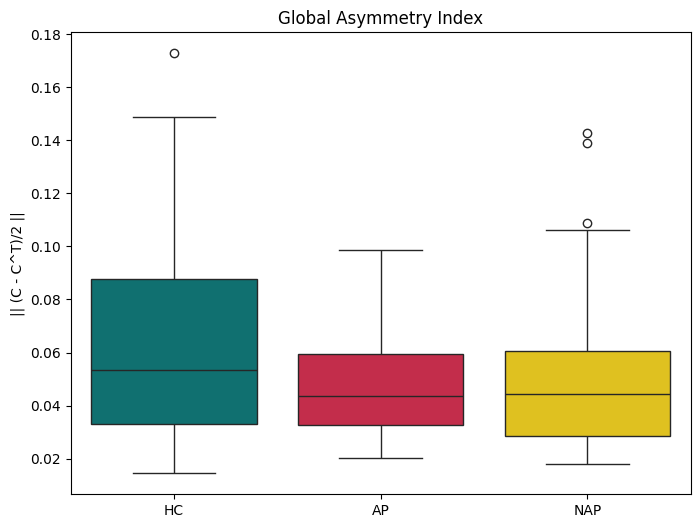

Mean Global Asymmetry for HC: 0.0640
Mean Global Asymmetry for AP: 0.0488
Mean Global Asymmetry for NAP: 0.0499


In [9]:
# Storage for asymmetry matrices and global indices
asym_results = {group: [] for group in study_results.keys()}
global_asym_index = {group: [] for group in study_results.keys()}

for group, subjects in study_results.items():
    for sub_id, data in subjects.items():
        C = data["GEC_matrix"]
        
        # Define Asymmetry as requested: (C - C.T) / 2
        C_asym = (C - C.T) / 2
        
        asym_results[group].append(C_asym)
        
        # Global Asymmetry Index: The Frobenius norm of the asymmetric part
        # This tells us the total 'strength' of directed flow in that brain
        index = np.linalg.norm(C_asym, ord='fro')
        global_asym_index[group].append(index)



plt.figure(figsize=(8, 6))
data_to_plot = [global_asym_index['HC'], global_asym_index['AP'], global_asym_index['NAP']]
sns.boxplot(data=data_to_plot, palette=['teal', 'crimson', 'gold'])
plt.xticks([0, 1, 2], ['HC', 'AP', 'NAP'])
plt.title("Global Asymmetry Index")
plt.ylabel("|| (C - C^T)/2 ||")
plt.show()

# Print mean values
for group in global_asym_index:
    print(f"Mean Global Asymmetry for {group}: {np.mean(global_asym_index[group]):.4f}")

Perturbability study

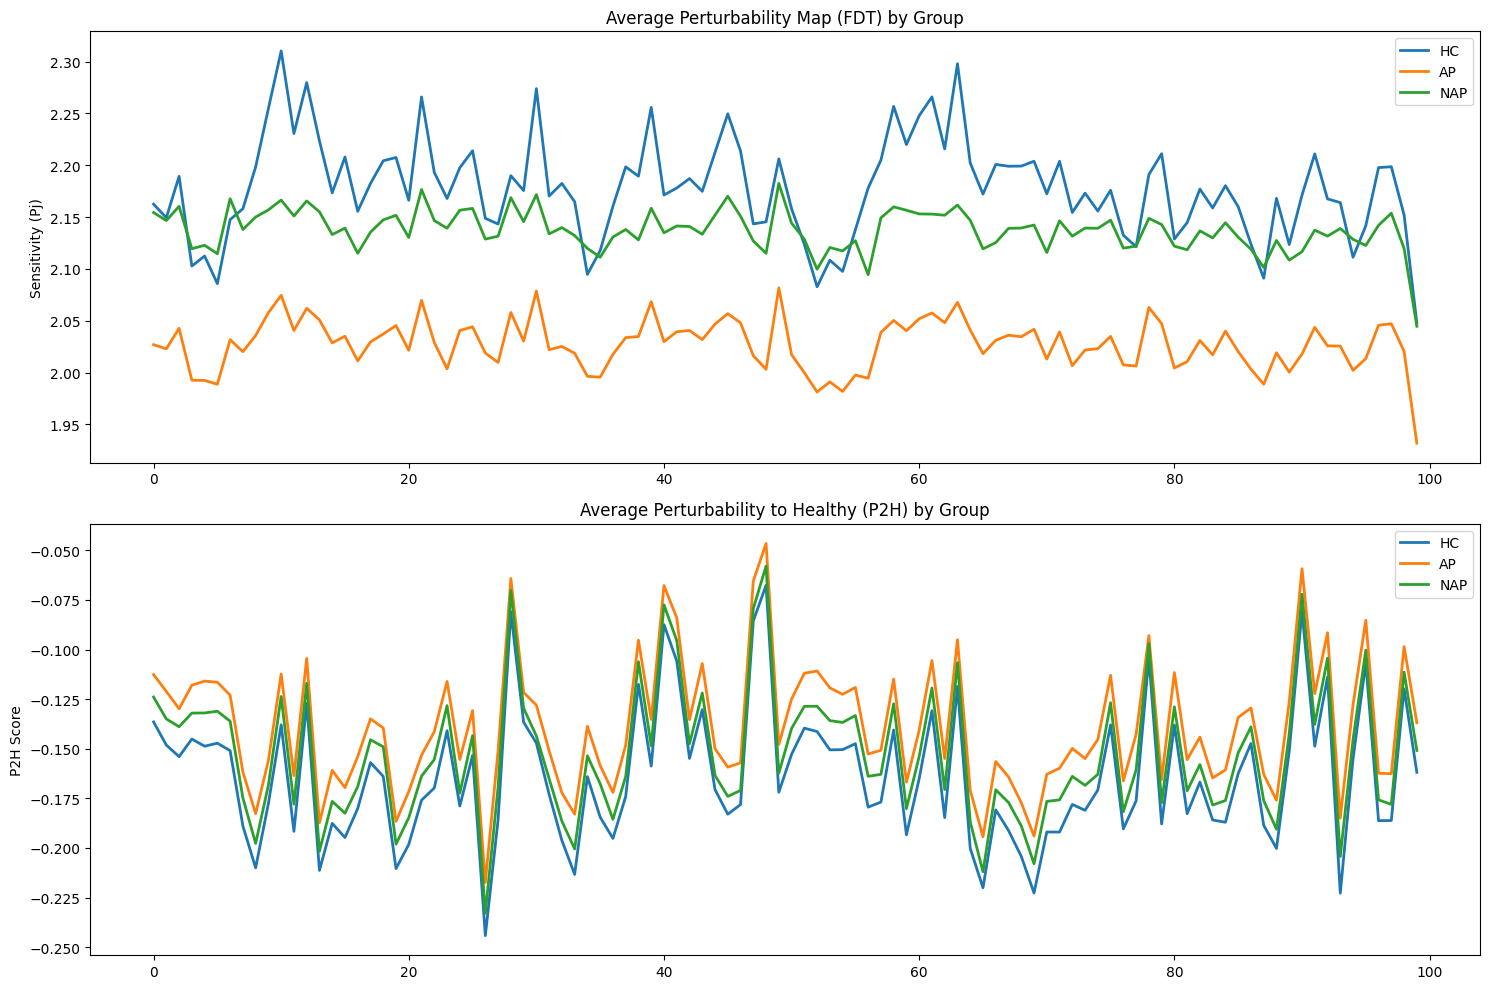

In [11]:
# Storage for group averages
group_p_avg = {}
group_p2h_avg = {}

for group in p_maps.keys():
    # p_maps[group] is a dict of {sub_id: array}
    # We stack them into a (n_subjects, 100) matrix and take the mean along axis 0
    p_stack = np.array(list(p_maps[group].values()))
    p2h_stack = np.array(list(p2h_maps[group].values()))
    
    group_p_avg[group] = np.mean(p_stack, axis=0)
    group_p2h_avg[group] = np.mean(p2h_stack, axis=0)


fig, ax = plt.subplots(2, 1, figsize=(15, 10))

# 1. Plot Perturbability (FDT) Group Comparison
for group in ['HC', 'AP', 'NAP']:
    ax[0].plot(group_p_avg[group], label=group, linewidth=2)
ax[0].set_title("Average Perturbability Map (FDT) by Group")
ax[0].set_ylabel("Sensitivity (Pj)")
ax[0].legend()

# 2. Plot P2H (Healing Potential) Group Comparison
for group in ['HC', 'AP', 'NAP']:
    ax[1].plot(group_p2h_avg[group], label=group, linewidth=2)
ax[1].set_title("Average Perturbability to Healthy (P2H) by Group")
ax[1].set_ylabel("P2H Score")
ax[1].legend()

plt.tight_layout()
plt.show()

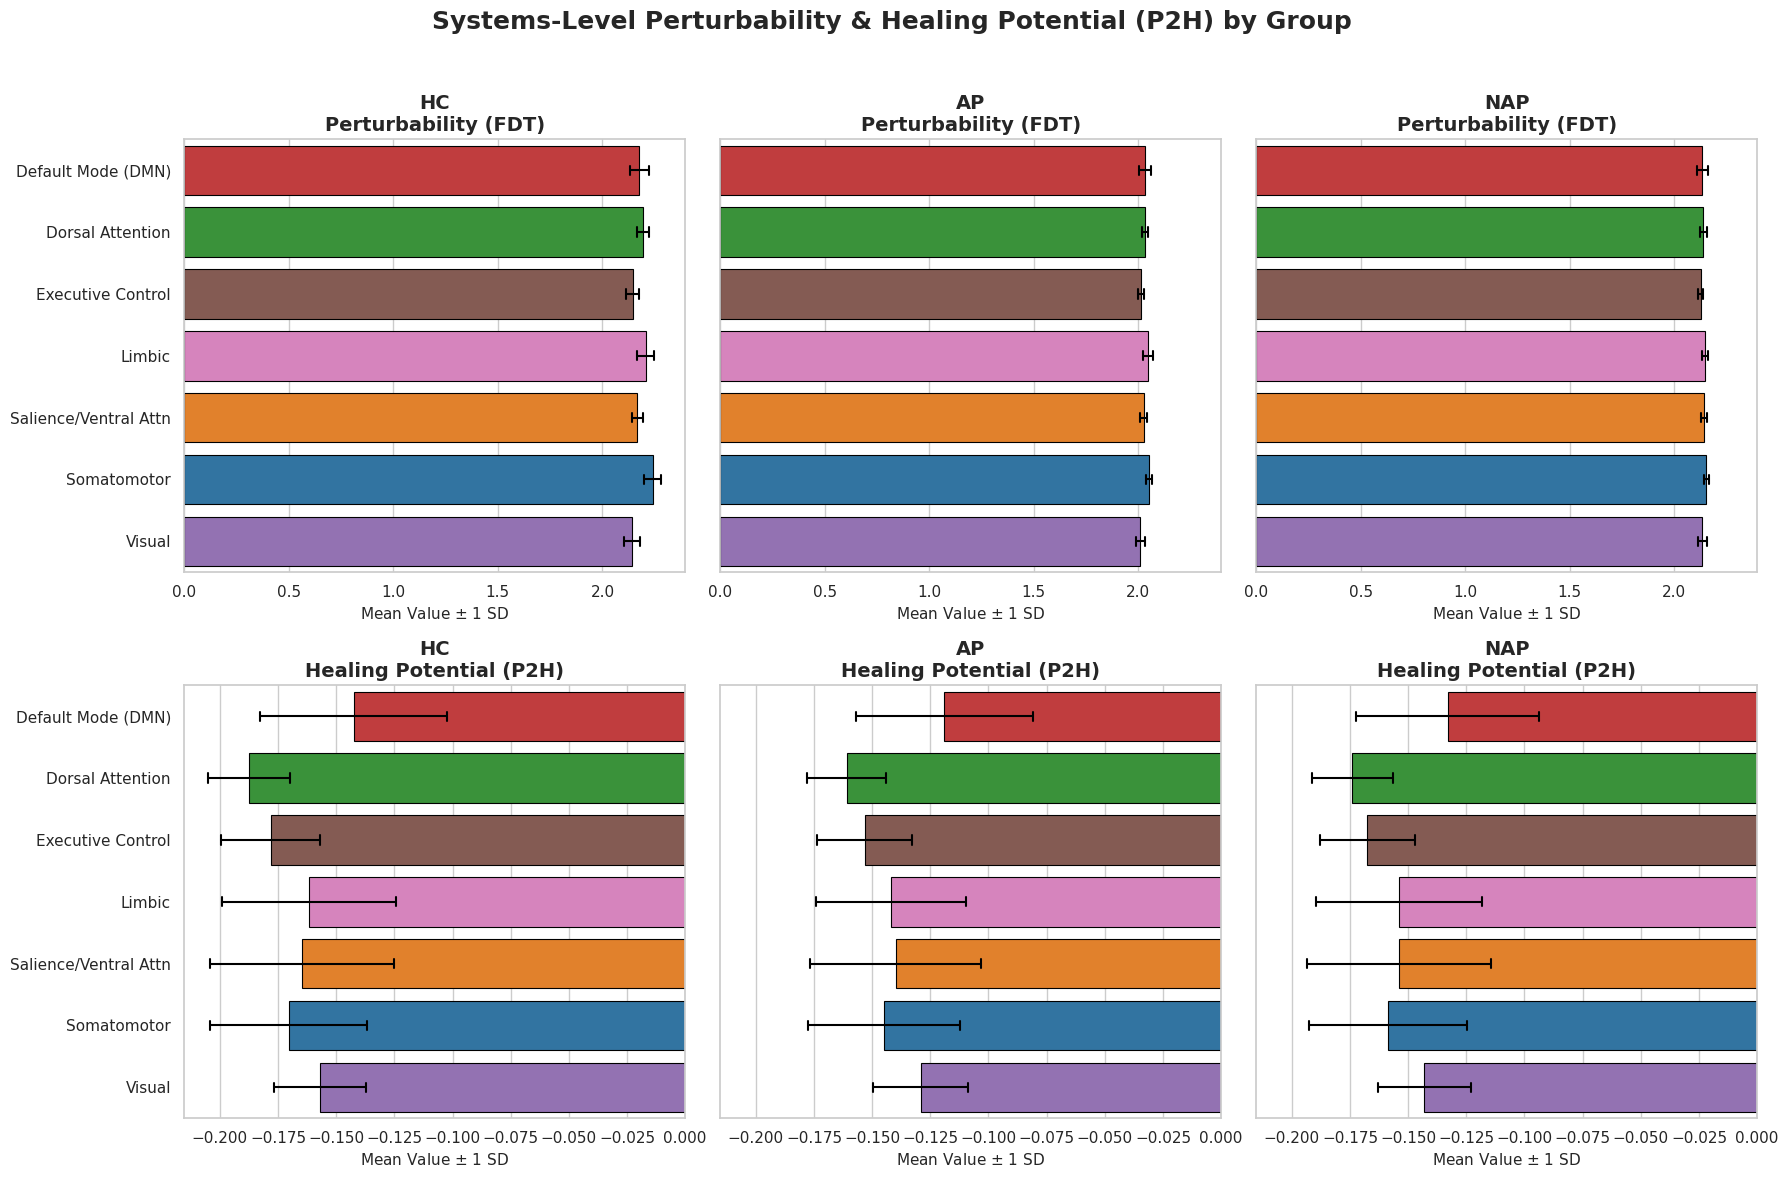

In [31]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Reuse the strict color map and order from earlier to ensure perfect consistency
network_colors = {
    'Default Mode (DMN)': '#d62728',
    'Dorsal Attention': '#2ca02c',
    'Executive Control': '#8c564b',
    'Limbic': '#e377c2',
    'Salience/Ventral Attn': '#ff7f0e',
    'Somatomotor': '#1f77b4',
    'Visual': '#9467bd'
}
network_order = sorted(network_colors.keys())

# ==========================================
# EXECUTION & GRID SETUP 
# ==========================================

# Create a 2x3 grid (Rows: Metrics, Cols: Groups)
# sharey=True ensures the network names only print once on the far left!
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 12), sharey=True)
fig.suptitle("Systems-Level Perturbability & Healing Potential (P2H) by Group", 
             fontsize=18, weight='bold', y=0.98)

groups = ['HC', 'AP', 'NAP']
metrics = [
    ('Perturbability (FDT)', p_maps), 
    ('Healing Potential (P2H)', p2h_maps)
]

for row_idx, (metric_name, data_dict) in enumerate(metrics):
    for col_idx, group in enumerate(groups):
        ax = axes[row_idx, col_idx]
        
        # 1. Stack subject arrays and average across subjects (axis=0) to get 100 region values
        stack = np.array(list(data_dict[group].values()))
        mean_across_subjects = np.mean(stack, axis=0) 
        
        # 2. Attach these 100 values to our macro-network lookup table
        df_plot = df_lookup.copy()
        df_plot['value'] = mean_across_subjects
        
        # 3. Plot with Seaborn (automatically groups the regions and computes mean + SD)
        sns.barplot(
            x='value', y='macro_network', data=df_plot, 
            ax=ax, palette=network_colors, order=network_order,
            hue='macro_network', legend=False, 
            edgecolor='black', linewidth=0.8,
            errorbar='sd', capsize=0.15, err_kws={'linewidth': 1.5, 'color': 'black'}
        )
        
        # 4. Formatting
        ax.set_title(f"{group}\n{metric_name}", fontsize=14, weight='bold')
        ax.set_xlabel(f"Mean Value $\\pm$ 1 SD", fontsize=11)
        ax.set_ylabel("") # Let the shared Y-axis handle this cleanly

# ==========================================
# ALIGN AXES FOR HONEST VISUAL COMPARISON
# ==========================================
# Loop through each row and force all 3 subplots to share the exact same X-axis scale
for row_idx in range(2):
    row_axes = axes[row_idx, :]
    
    # Find the absolute minimum and maximum X limits across the HC, AP, NAP plots
    x_min = min([ax.get_xlim()[0] for ax in row_axes])
    x_max = max([ax.get_xlim()[1] for ax in row_axes])
    
    # Apply those absolute bounds back to the plots
    for ax in row_axes:
        ax.set_xlim(x_min, x_max)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

CLinical Scores study

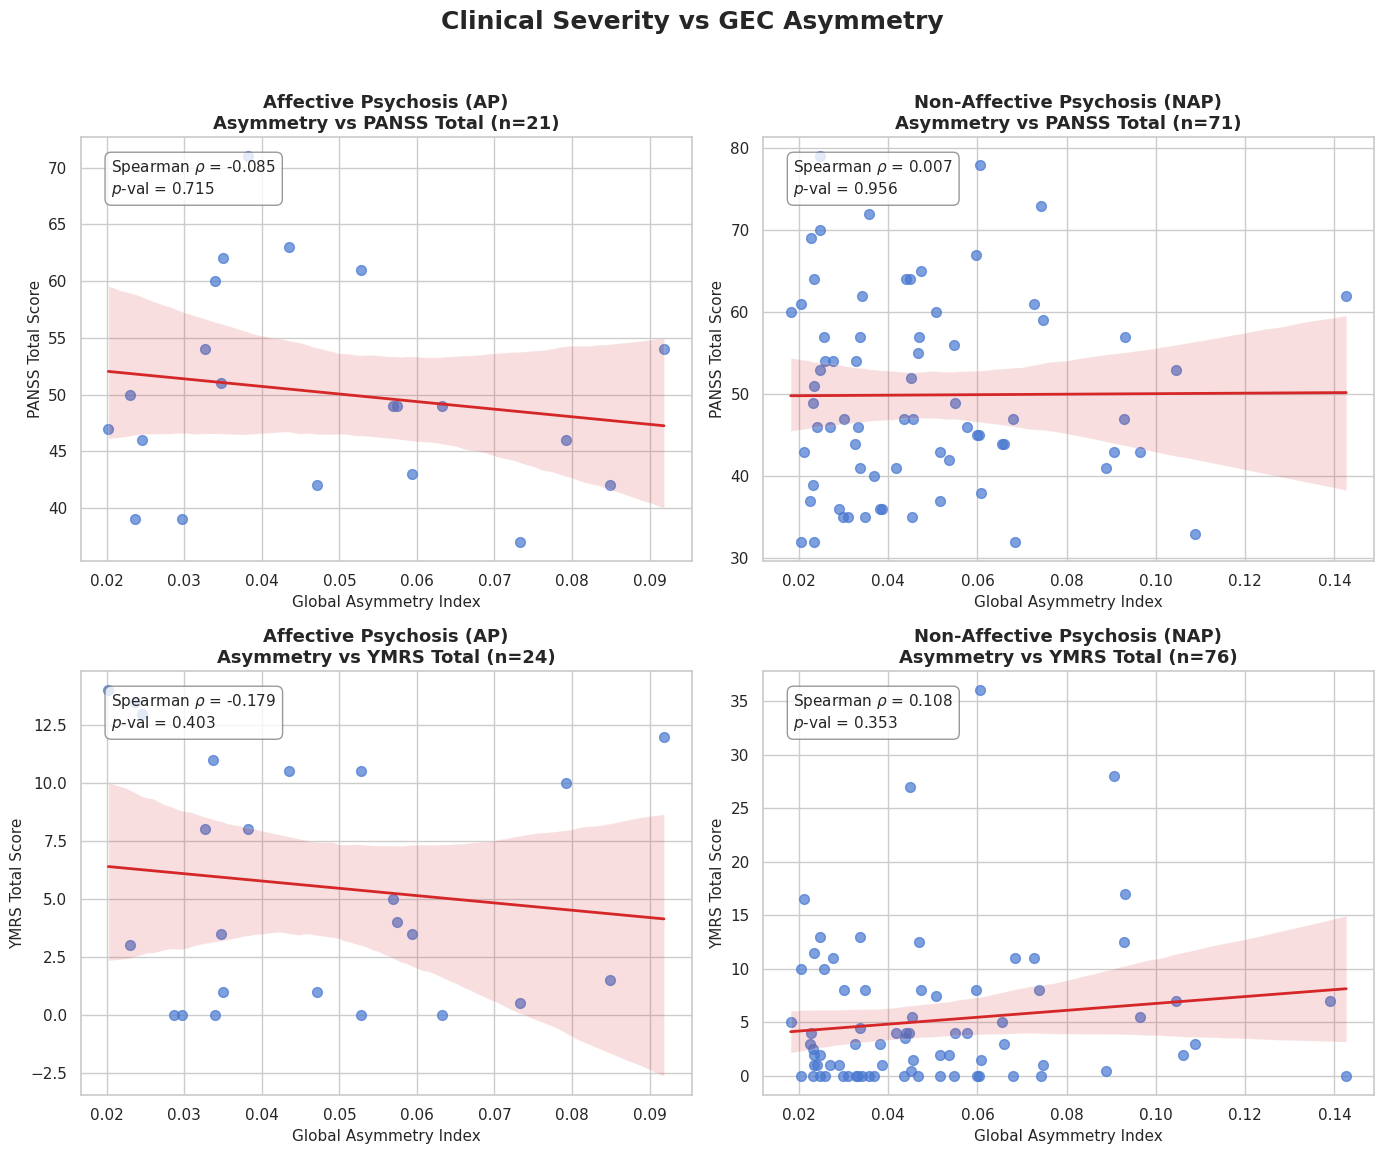

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

# Set a clean seaborn aesthetic for publication-ready plots
sns.set_theme(style="whitegrid", palette="muted")

def plot_correlation_on_axis(ax, x_data, y_data, group_name, metric_name, n_subjects=100):
    """Helper function to clean data, compute correlation, and plot on a specific subplot axis."""
    
    # 1. Slice the data to the desired number of subjects
    x = np.array(x_data[:n_subjects])
    y = np.array(y_data[:n_subjects])
    
    # 2. Clean NaNs
    mask = ~np.isnan(x) & ~np.isnan(y)
    x_clean = x[mask]
    y_clean = y[mask]
    
    # Check if we have enough data points
    if len(x_clean) < 3:
        ax.set_title(f"{group_name} - {metric_name}\n(Not enough valid data)", color="red")
        return np.nan, np.nan

    # 3. Compute Spearman Correlation
    r_val, p_val = spearmanr(x_clean, y_clean)
    
    # 4. Plotting on the specific Axis (ax)
    sns.regplot(
        x=x_clean, y=y_clean, ax=ax, 
        scatter_kws={'alpha': 0.7, 's': 50}, 
        line_kws={'color': '#d62728', 'linewidth': 2}
    )
    
    # 5. Dynamic and informative titles/labels
    ax.set_title(f"{group_name}\nAsymmetry vs {metric_name} (n={len(x_clean)})", fontsize=13, weight='bold')
    ax.set_xlabel("Global Asymmetry Index", fontsize=11)
    ax.set_ylabel(f"{metric_name} Score", fontsize=11)
    
    # Annotate stats in the top left corner
    stats_text = f'Spearman $\\rho$ = {r_val:.3f}\n$p$-val = {p_val:.3f}'
    ax.annotate(
        stats_text, 
        xy=(0.05, 0.95), xycoords='axes fraction', 
        verticalalignment='top',
        bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="gray", alpha=0.8),
        fontsize=11
    )
    
    return r_val, p_val

# ==========================================
# EXECUTION & GRID SETUP
# ==========================================

# Create a 2x2 grid of subplots
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 12))
fig.suptitle("Clinical Severity vs GEC Asymmetry", fontsize=18, weight='bold', y=0.96)

# Row 1: PANSS Total Scores
r_ap_panss, p_ap_panss = plot_correlation_on_axis(
    axes[0, 0], global_asym_index['AP'], panss_AP, 'Affective Psychosis (AP)', 'PANSS Total'
)
r_nap_panss, p_nap_panss = plot_correlation_on_axis(
    axes[0, 1], global_asym_index['NAP'], panss_NAP, 'Non-Affective Psychosis (NAP)', 'PANSS Total'
)

# Row 2: YMRS Total Scores
r_ap_ymrs, p_ap_ymrs = plot_correlation_on_axis(
    axes[1, 0], global_asym_index['AP'], ymrs_AP, 'Affective Psychosis (AP)', 'YMRS Total'
)
r_nap_ymrs, p_nap_ymrs = plot_correlation_on_axis(
    axes[1, 1], global_asym_index['NAP'], ymrs_NAP, 'Non-Affective Psychosis (NAP)', 'YMRS Total'
)

# Adjust spacing so titles and axis labels don't overlap
plt.tight_layout(rect=[0, 0, 1, 0.94]) 
plt.show()

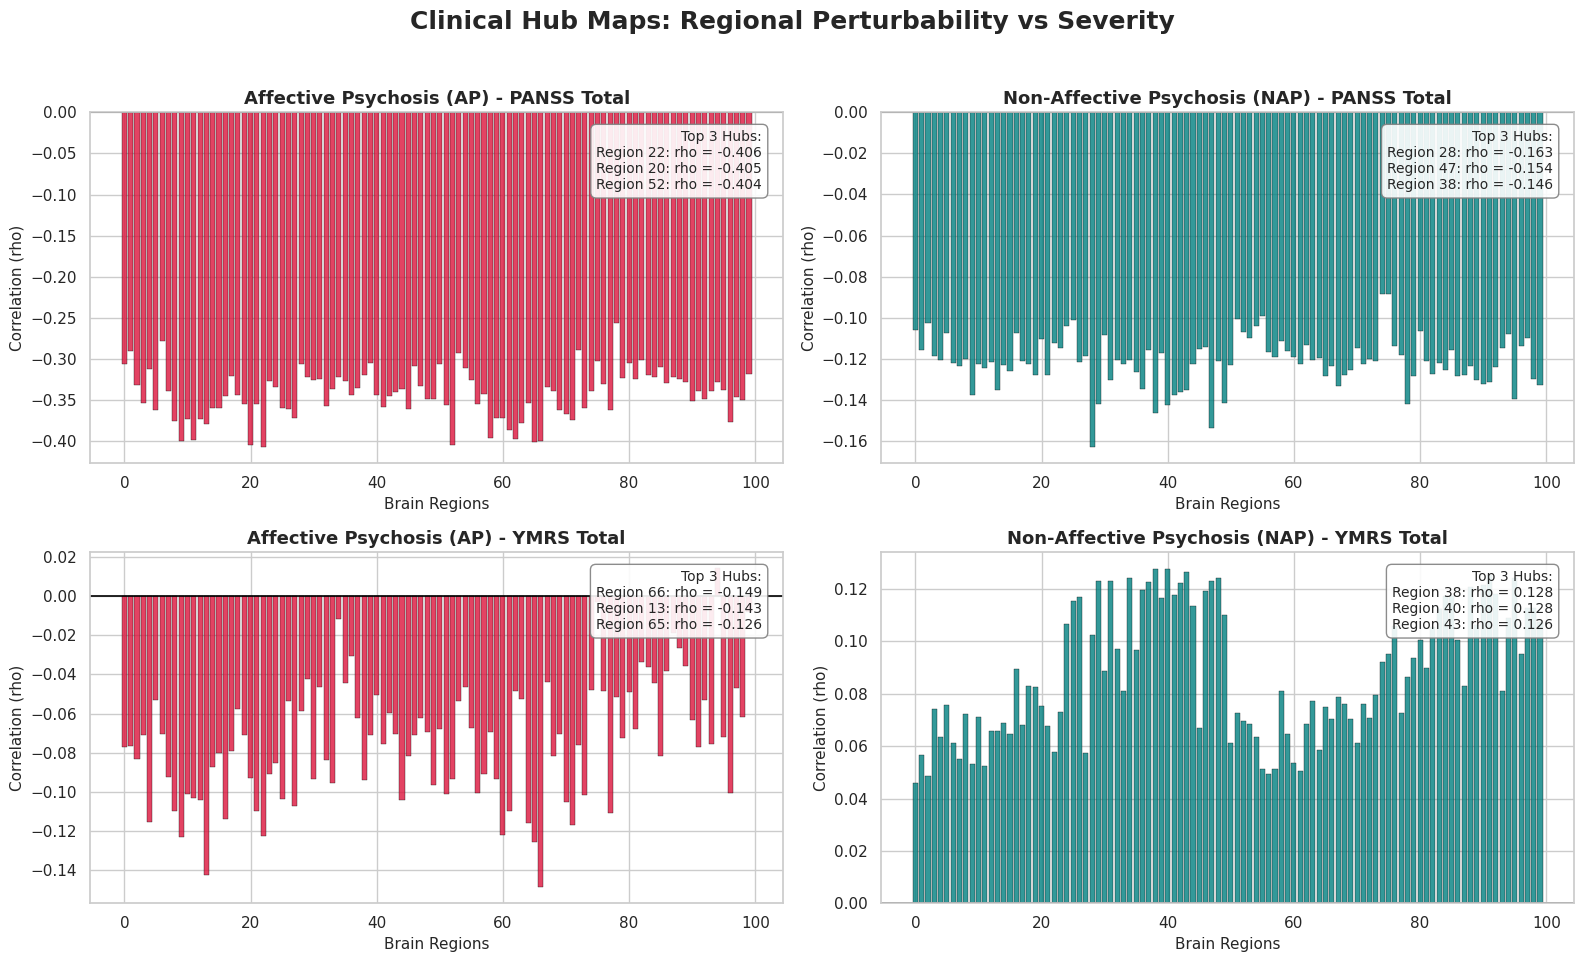

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

# Set clean visual aesthetic
sns.set_theme(style="whitegrid", palette="muted")

def find_clinical_hubs(p_maps_group, clinical_scores, n_subjects=None):
    """Calculates regional correlation between perturbability and clinical scores."""
    # Convert dictionary to matrix and slice if n_subjects is provided
    p_matrix = np.array(list(p_maps_group.values()))
    scores = np.array(clinical_scores)
    
    if n_subjects is not None:
        p_matrix = p_matrix[:n_subjects]
        scores = scores[:n_subjects]
        
    n_regions = p_matrix.shape[1]
    region_rhos = np.zeros(n_regions)
    region_ps = np.zeros(n_regions)
    
    for j in range(n_regions):
        x = p_matrix[:, j]
        y = scores
        
        # Mask out NaNs for this specific region-score pair
        mask = ~np.isnan(x) & ~np.isnan(y)
        
        if np.sum(mask) > 3:
            rho, p = spearmanr(x[mask], y[mask])
            region_rhos[j] = rho
            region_ps[j] = p
        else:
            region_rhos[j], region_ps[j] = np.nan, np.nan
            
    return region_rhos, region_ps

def plot_hub_map_on_axis(ax, p_maps_group, clinical_scores, group_name, metric_name, color):
    """Computes hubs and plots the bar chart onto a specific subplot axis."""
    # Compute correlations
    rhos, ps = find_clinical_hubs(p_maps_group, clinical_scores)
    
    n_regions = len(rhos)
    regions = np.arange(n_regions)
    
    # Plot the bar chart
    ax.bar(regions, rhos, color=color, alpha=0.8, edgecolor='black', linewidth=0.3)
    ax.axhline(0, color='black', linewidth=1.2)
    
    # Formatting
    ax.set_title(f"{group_name} - {metric_name}", fontsize=13, weight='bold')
    ax.set_xlabel("Brain Regions", fontsize=11)
    ax.set_ylabel("Correlation (rho)", fontsize=11)
    
    # Safely find and annotate the top 3 hubs (ignoring NaNs)
    valid_idx = np.where(~np.isnan(rhos))[0]
    if len(valid_idx) >= 3:
        # Sort valid indices by their absolute correlation value
        sorted_valid = valid_idx[np.argsort(np.abs(rhos[valid_idx]))]
        top_3 = sorted_valid[-3:][::-1] # Grab last 3 and reverse for descending order
        
        # Format the text box
        top_text = "Top 3 Hubs:\n" + "\n".join([f"Region {r}: rho = {rhos[r]:.3f}" for r in top_3])
        
        ax.annotate(
            top_text, 
            xy=(0.97, 0.95), xycoords='axes fraction', 
            horizontalalignment='right', verticalalignment='top',
            bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="gray", alpha=0.9),
            fontsize=10
        )

# ==========================================
# EXECUTION & GRID SETUP
# ==========================================

# Create a 2x2 grid of subplots
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 10))
fig.suptitle("Clinical Hub Maps: Regional Perturbability vs Severity", fontsize=18, weight='bold', y=0.96)

# Row 1: PANSS Total Scores
plot_hub_map_on_axis(
    axes[0, 0], p_maps['AP'], panss_AP, 'Affective Psychosis (AP)', 'PANSS Total', color='crimson'
)
plot_hub_map_on_axis(
    axes[0, 1], p_maps['NAP'], panss_NAP, 'Non-Affective Psychosis (NAP)', 'PANSS Total', color='teal'
)

# Row 2: YMRS Total Scores
plot_hub_map_on_axis(
    axes[1, 0], p_maps['AP'], ymrs_AP, 'Affective Psychosis (AP)', 'YMRS Total', color='crimson'
)
plot_hub_map_on_axis(
    axes[1, 1], p_maps['NAP'], ymrs_NAP, 'Non-Affective Psychosis (NAP)', 'YMRS Total', color='teal'
)

# Adjust spacing to prevent overlapping elements
plt.tight_layout(rect=[0, 0, 1, 0.94]) 
plt.show()

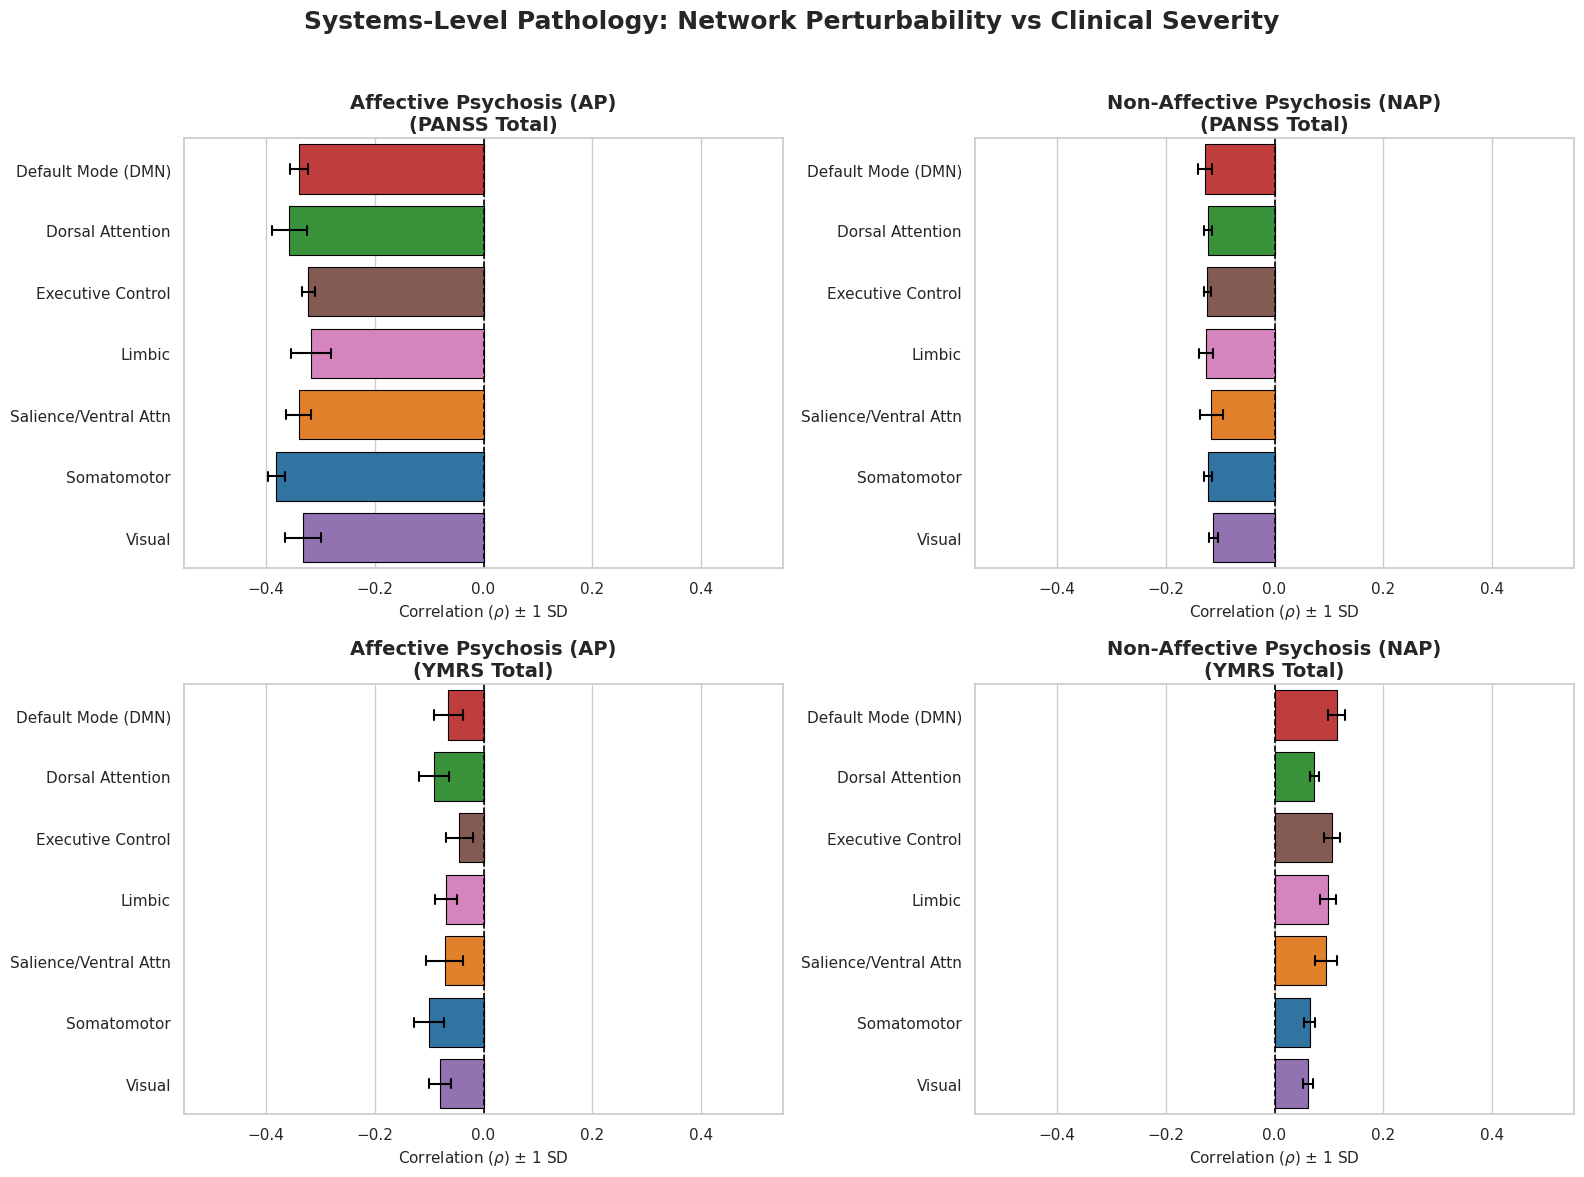

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
import numpy as np

# Set clean visual aesthetic
sns.set_theme(style="whitegrid", palette="muted")

# Define a strict, consistent color map for the 7 macro-networks
network_colors = {
    'Default Mode (DMN)': '#d62728',       # Red
    'Dorsal Attention': '#2ca02c',         # Green
    'Executive Control': '#8c564b',        # Brown
    'Limbic': '#e377c2',                   # Pink
    'Salience/Ventral Attn': '#ff7f0e',    # Orange
    'Somatomotor': '#1f77b4',              # Blue
    'Visual': '#9467bd'                    # Purple
}

# Alphabetical order to ensure identical layout across all subplots
network_order = sorted(network_colors.keys())

def find_clinical_hubs(p_maps_group, clinical_scores):
    """Calculates regional correlation for all 100 regions."""
    p_matrix = np.array(list(p_maps_group.values()))
    scores = np.array(clinical_scores)
    n_regions = p_matrix.shape[1]
    region_rhos = np.zeros(n_regions)
    
    for j in range(n_regions):
        # Mask out NaNs to ensure clean correlation math
        mask = ~np.isnan(p_matrix[:, j]) & ~np.isnan(scores)
        if np.sum(mask) > 3:
            rho, _ = spearmanr(p_matrix[mask, j], scores[mask])
            region_rhos[j] = rho
        else:
            region_rhos[j] = np.nan
            
    return region_rhos

def plot_macro_networks_on_axis(ax, p_maps_group, clinical_scores, group_name, metric_name, df_lookup):
    """Plots network-level averages with standard deviation error bars."""
    # Compute the raw 100 region rhos
    rhos = find_clinical_hubs(p_maps_group, clinical_scores)
    
    # Attach the correlations to our macro-network lookup table
    df_analysis = df_lookup.copy()
    df_analysis['rho'] = rhos
    
    # Plot raw data directly. Seaborn calculates the mean and standard deviation automatically.
    sns.barplot(
        x='rho', y='macro_network', data=df_analysis, 
        ax=ax, palette=network_colors, order=network_order,
        hue='macro_network', legend=False, 
        edgecolor='black', linewidth=0.8,
        errorbar='sd', capsize=0.15, err_kws={'linewidth': 1.5, 'color': 'black'}
    )
    
    # Formatting
    ax.axvline(0, color='black', linewidth=1.2, linestyle='--')
    ax.set_title(f"{group_name}\n({metric_name})", fontsize=14, weight='bold')
    ax.set_xlabel("Correlation ($\\rho$) $\\pm$ 1 SD", fontsize=11)
    ax.set_ylabel("") 
    
    # Lock the x-axis to absolute correlation bounds for honest visual comparison
    ax.set_xlim(-0.55, 0.55)

# ==========================================
# EXECUTION & GRID SETUP (Macro-Scale)
# ==========================================

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 12))
fig.suptitle("Systems-Level Pathology: Network Perturbability vs Clinical Severity", 
             fontsize=18, weight='bold', y=0.98)

# Row 1: PANSS Total Scores
plot_macro_networks_on_axis(
    axes[0, 0], p_maps['AP'], panss_AP, 'Affective Psychosis (AP)', 'PANSS Total', df_lookup
)
plot_macro_networks_on_axis(
    axes[0, 1], p_maps['NAP'], panss_NAP, 'Non-Affective Psychosis (NAP)', 'PANSS Total', df_lookup
)

# Row 2: YMRS Total Scores
plot_macro_networks_on_axis(
    axes[1, 0], p_maps['AP'], ymrs_AP, 'Affective Psychosis (AP)', 'YMRS Total', df_lookup
)
plot_macro_networks_on_axis(
    axes[1, 1], p_maps['NAP'], ymrs_NAP, 'Non-Affective Psychosis (NAP)', 'YMRS Total', df_lookup
)

# Adjust spacing so the long network names fit perfectly on the y-axis
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

P2H distribution anaysis

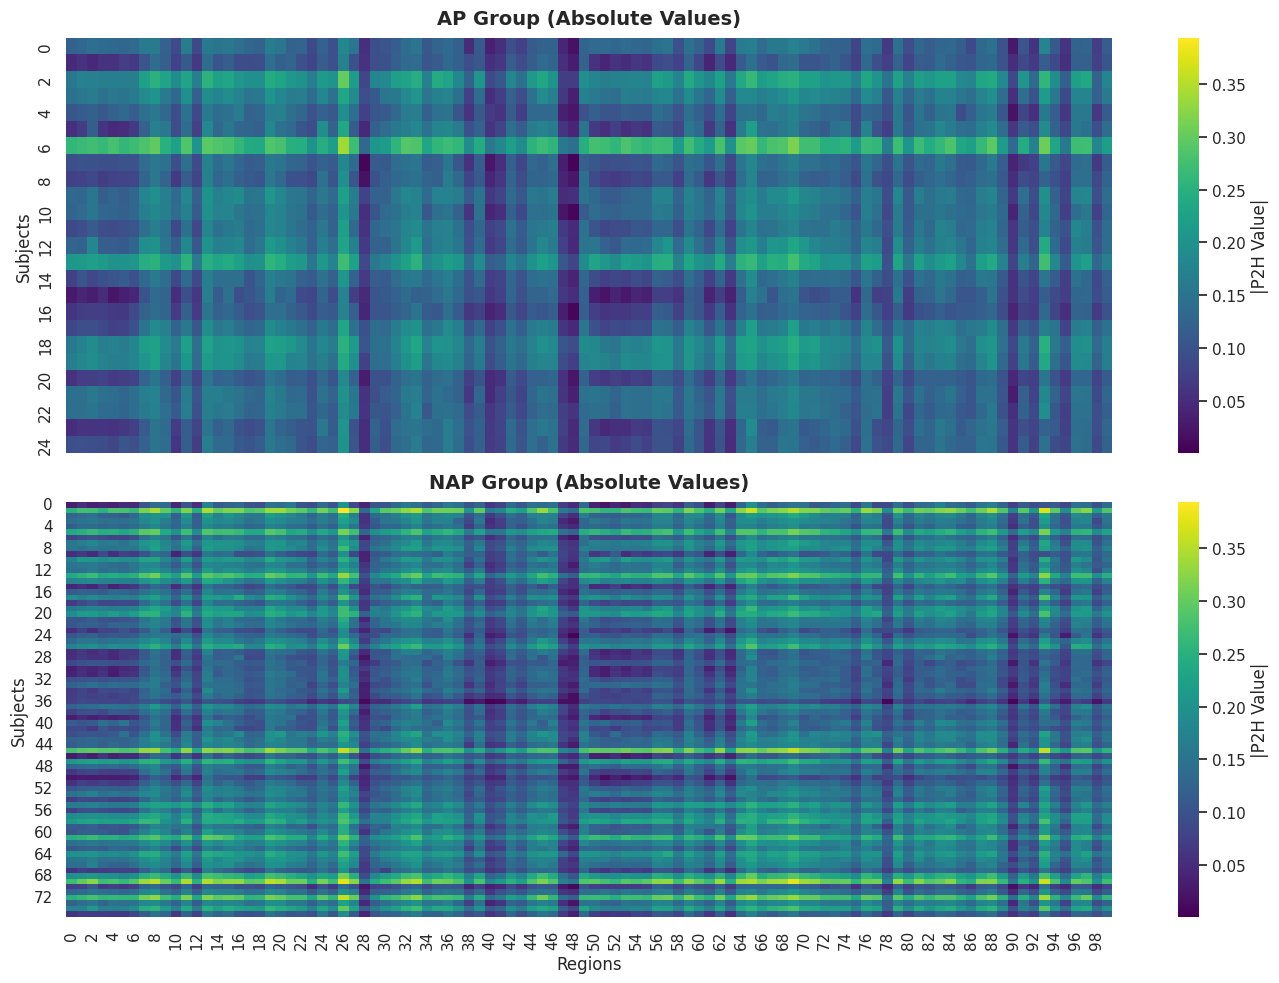

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Prepare the data matrices with absolute values ---
subjects_ap = sorted(p2h_maps['AP'].keys())
# Apply np.abs to take the absolute values
matrix_ap = np.abs(np.vstack([p2h_maps['AP'][s] for s in subjects_ap]))

subjects_nap = sorted(p2h_maps['NAP'].keys())
# Apply np.abs to take the absolute values
matrix_nap = np.abs(np.vstack([p2h_maps['NAP'][s] for s in subjects_nap]))

# --- 2. Define consistent color limits ---
vmin = min(matrix_ap.min(), matrix_nap.min())
vmax = max(matrix_ap.max(), matrix_nap.max())

# --- 3. Plotting the subplots ---
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(14, 10), sharex=True)

cmap_choice = 'viridis' 

# Subplot 1: AP Group
sns.heatmap(matrix_ap, ax=axes[0], cmap=cmap_choice, vmin=vmin, vmax=vmax,
            cbar_kws={'label': '|P2H Value|'})
axes[0].set_title('AP Group (Absolute Values)', fontsize=14, fontweight='bold', pad=10)
axes[0].set_ylabel('Subjects', fontsize=12)

# Subplot 2: NAP Group
sns.heatmap(matrix_nap, ax=axes[1], cmap=cmap_choice, vmin=vmin, vmax=vmax,
            cbar_kws={'label': '|P2H Value|'})
axes[1].set_title('NAP Group (Absolute Values)', fontsize=14, fontweight='bold', pad=10)
axes[1].set_ylabel('Subjects', fontsize=12)
axes[1].set_xlabel('Regions', fontsize=12)

plt.tight_layout()

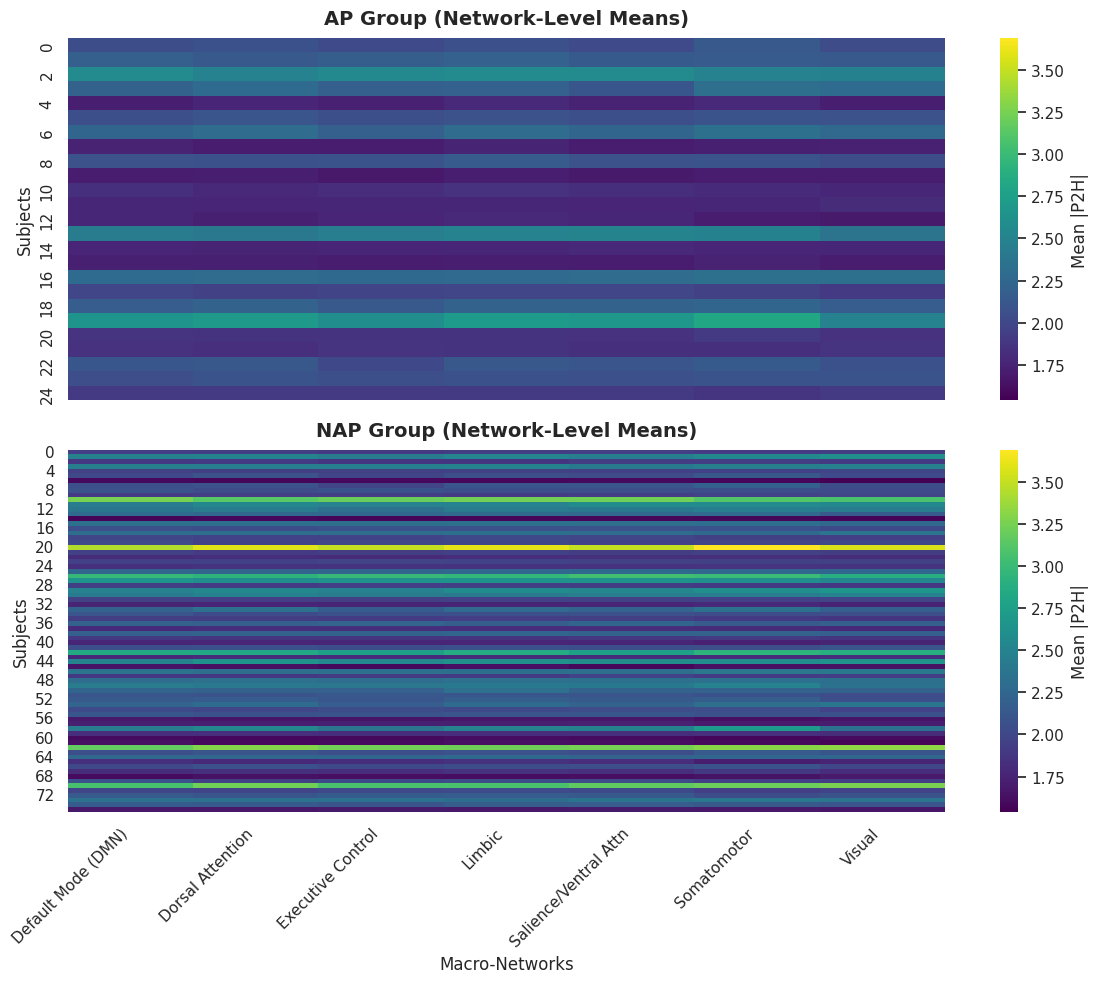

In [38]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Helper function to aggregate 100 regions into 7 macro-networks ---
def get_network_matrix(p_maps_group, df_lookup, network_order):
    subjects = sorted(p_maps_group.keys())
    # Stack into a (subjects, 100 regions) matrix and apply absolute values
    matrix_100 = np.abs(np.vstack([p_maps_group[s] for s in subjects]))
    
    # Get network assignments aligned with the 100 regions
    networks = df_lookup['macro_network'].values
    
    # Compute the mean of regions belonging to each network
    matrix_net = []
    for net in network_order:
        region_indices = np.where(networks == net)[0]
        net_mean = np.mean(matrix_100[:, region_indices], axis=1)
        matrix_net.append(net_mean)
        
    return np.column_stack(matrix_net)

# --- 2. Process both groups ---
# network_order is already defined alphabetically from your snippet
matrix_ap_net = get_network_matrix(p_maps['AP'], df_lookup, network_order)
matrix_nap_net = get_network_matrix(p_maps['NAP'], df_lookup, network_order)

# --- 3. Define consistent color limits ---
vmin = min(matrix_ap_net.min(), matrix_nap_net.min())
vmax = max(matrix_ap_net.max(), matrix_nap_net.max())

# --- 4. Plotting the Macro-Network Matrices ---
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(12, 10), sharex=True)

cmap_choice = 'viridis'

# Subplot 1: AP Group
sns.heatmap(matrix_ap_net, ax=axes[0], cmap=cmap_choice, vmin=vmin, vmax=vmax,
            xticklabels=network_order, cbar_kws={'label': 'Mean |P2H|'})
axes[0].set_title('AP Group (Network-Level Means)', fontsize=14, fontweight='bold', pad=10)
axes[0].set_ylabel('Subjects', fontsize=12)

# Subplot 2: NAP Group
sns.heatmap(matrix_nap_net, ax=axes[1], cmap=cmap_choice, vmin=vmin, vmax=vmax,
            xticklabels=network_order, cbar_kws={'label': 'Mean |P2H|'})
axes[1].set_title('NAP Group (Network-Level Means)', fontsize=14, fontweight='bold', pad=10)
axes[1].set_ylabel('Subjects', fontsize=12)
axes[1].set_xlabel('Macro-Networks', fontsize=12)

# Rotate X-axis labels so the long network names fit cleanly
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.savefig('p2h_macro_networks_absolute_heatmap.png', dpi=300)
plt.show()

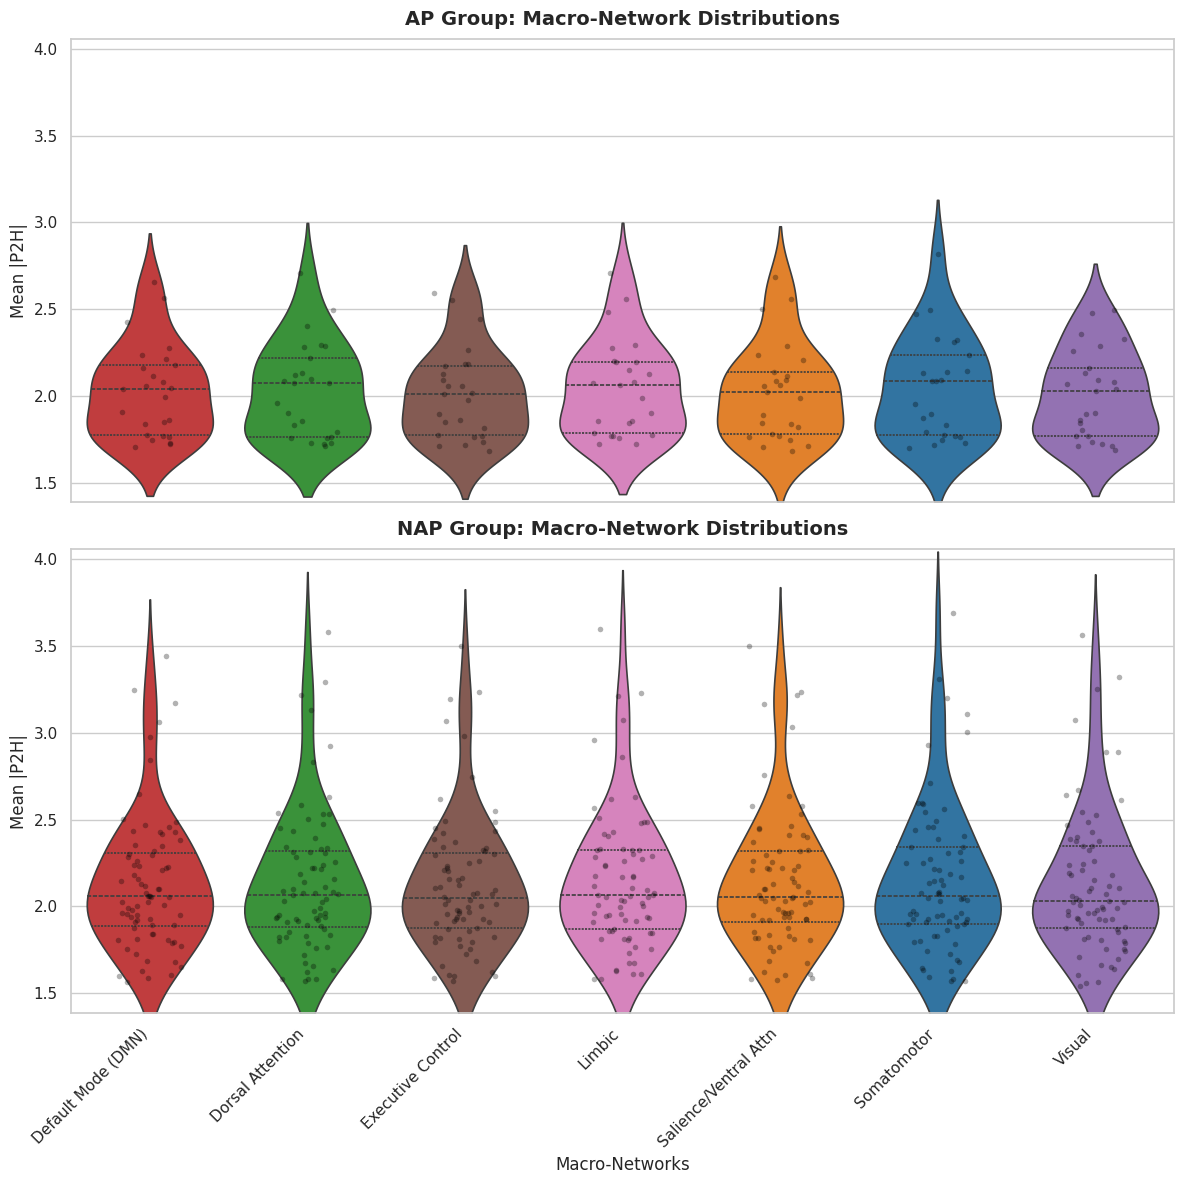

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set clean visual aesthetic
sns.set_theme(style="whitegrid", palette="muted")

# --- 1. Helper function to create a long-form DataFrame of network means ---
def get_network_df(p_maps_group, df_lookup, group_name):
    subjects = sorted(p_maps_group.keys())
    # Stack into a (subjects, 100 regions) matrix and apply absolute values
    matrix_100 = np.abs(np.vstack([p_maps_group[s] for s in subjects]))
    networks = df_lookup['macro_network'].values
    
    data_rows = []
    for i, subj in enumerate(subjects):
        for net in network_order:
            # Gather indices belonging to the current macro-network
            region_indices = np.where(networks == net)[0]
            # Calculate the subject's mean absolute P2H score for this network
            net_mean = np.mean(matrix_100[i, region_indices])
            data_rows.append({
                'Subject': subj,
                'Network': net,
                'Mean_Absolute_P2H': net_mean,
                'Group': group_name
            })
            
    return pd.DataFrame(data_rows)

# --- 2. Process both groups into DataFrames ---
# network_order and network_colors are already defined in your environment
df_ap = get_network_df(p_maps['AP'], df_lookup, 'AP')
df_nap = get_network_df(p_maps['NAP'], df_lookup, 'NAP')

# Find a common Y-axis limit for accurate across-group comparison
y_min = min(df_ap['Mean_Absolute_P2H'].min(), df_nap['Mean_Absolute_P2H'].min()) * 0.9
y_max = max(df_ap['Mean_Absolute_P2H'].max(), df_nap['Mean_Absolute_P2H'].max()) * 1.1

# --- 3. Plotting the distributions (Violin + Strip Plots) ---
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(12, 12), sharex=True)

# Subplot 1: AP Group Distributions
sns.violinplot(
    data=df_ap, x='Network', y='Mean_Absolute_P2H', ax=axes[0],
    palette=network_colors, order=network_order, hue='Network', legend=False,
    inner='quartile', linewidth=1.2
)
sns.stripplot(
    data=df_ap, x='Network', y='Mean_Absolute_P2H', ax=axes[0],
    order=network_order, color='black', alpha=0.3, jitter=0.2, size=4
)
axes[0].set_title('AP Group: Macro-Network Distributions', fontsize=14, fontweight='bold', pad=10)
axes[0].set_ylabel('Mean |P2H|', fontsize=12)
axes[0].set_ylim(y_min, y_max)
axes[0].set_xlabel('')

# Subplot 2: NAP Group Distributions
sns.violinplot(
    data=df_nap, x='Network', y='Mean_Absolute_P2H', ax=axes[1],
    palette=network_colors, order=network_order, hue='Network', legend=False,
    inner='quartile', linewidth=1.2
)
sns.stripplot(
    data=df_nap, x='Network', y='Mean_Absolute_P2H', ax=axes[1],
    order=network_order, color='black', alpha=0.3, jitter=0.2, size=4
)
axes[1].set_title('NAP Group: Macro-Network Distributions', fontsize=14, fontweight='bold', pad=10)
axes[1].set_ylabel('Mean |P2H|', fontsize=12)
axes[1].set_ylim(y_min, y_max)
axes[1].set_xlabel('Macro-Networks', fontsize=12)

# Rotate and align X-axis labels cleanly
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.savefig('p2h_macro_networks_distributions.png', dpi=300)
plt.show()


p2O and p2H maps 

In [41]:
import numpy as np
import pandas as pd
from scipy.stats import pearsonr

N_REGIONS = 100 
co_occurrence_matrix = np.zeros((N_REGIONS, N_REGIONS))
metrics_list = []

for group_name, subjects in p2h_maps.items():
    for subj_idx in subjects.keys():
        p2h = p2h_maps[group_name][subj_idx]
        p2o = p2o_maps[group_name][subj_idx]
        
        # 1. Calculate Target Regions
        node_p2h_min = np.argmin(p2h) # Region minimizing distance to healthy
        node_p2o_max = np.argmax(p2o) # Region maximizing distance from origin
        
        # 2. Populate the N x N Map
        co_occurrence_matrix[node_p2h_min, node_p2o_max] += 1
        
        # 3. Calculate Correlation between the maps
        r_val, p_val = pearsonr(p2h, p2o)
        
        # Store data
        metrics_list.append({
            "Subject_ID": f"{group_name}_{subj_idx}",
            "Group": group_name,
            "Node_p2h_min": node_p2h_min,
            "Val_p2h_min": p2h[node_p2h_min],
            "Node_p2o_max": node_p2o_max,
            "Val_p2o_max": p2o[node_p2o_max],
            "P2H_P2O_Correlation": r_val
        })

df_metrics = pd.DataFrame(metrics_list)
# Display the first few rows to verify
df_metrics.head()

,Subject_ID,Group,Node_p2h_min,Val_p2h_min,Node_p2o_max,Val_p2o_max,P2H_P2O_Correlation
0,HC_0,HC,26,-0.235508,26,0.364417,-0.660850
1,HC_1,HC,26,-0.236905,36,0.376338,-0.560112
2,HC_2,HC,26,-0.225171,36,0.371255,-0.376002
3,HC_3,HC,26,-0.174907,92,0.266760,-0.411935
4,HC_4,HC,26,-0.240934,8,0.438652,-0.539000


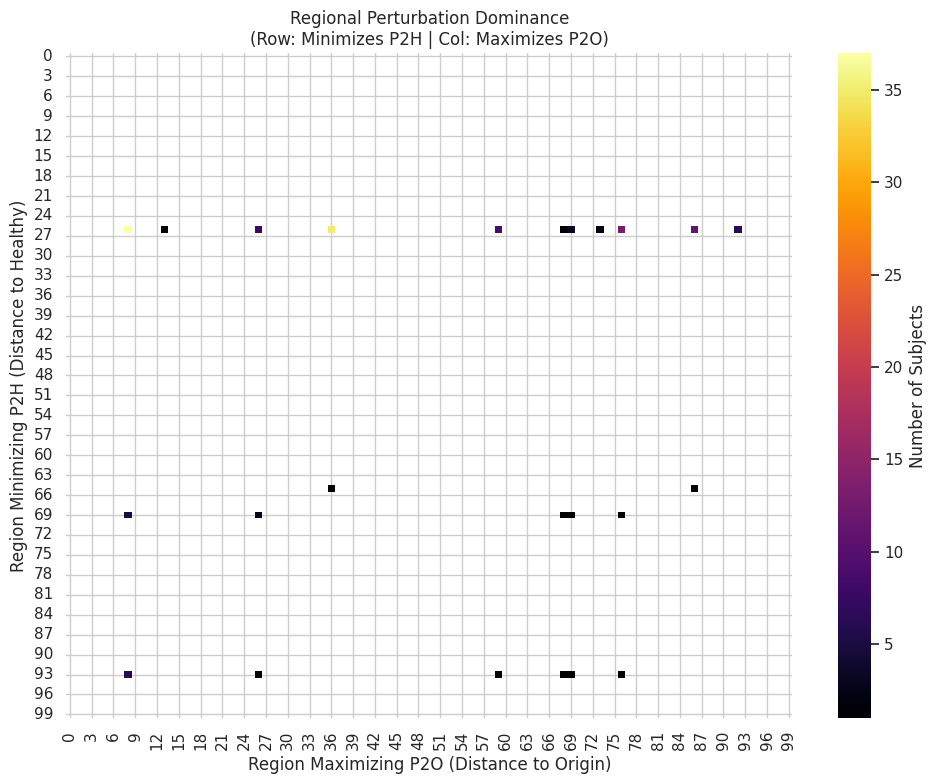

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))
sns.heatmap(
    co_occurrence_matrix, 
    cmap="inferno", 
    mask=co_occurrence_matrix == 0, 
    cbar_kws={'label': 'Number of Subjects'}
)
plt.title("Regional Perturbation Dominance\n(Row: Minimizes P2H | Col: Maximizes P2O)")
plt.xlabel("Region Maximizing P2O (Distance to Origin)")
plt.ylabel("Region Minimizing P2H (Distance to Healthy)")
plt.tight_layout()
plt.show()

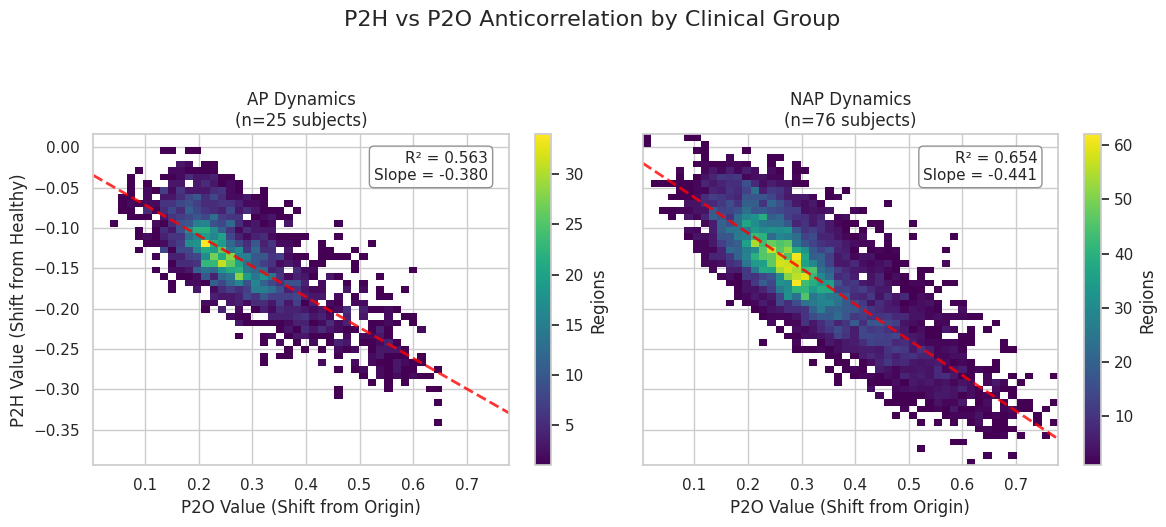

In [53]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import linregress

# 1. Define the groups to plot
# groups = ['HC', 'AP', 'NAP']
groups = ['AP', 'NAP']

# 2. First pass: Collect data to find global min/max so all plots share the exact same scale
global_p2h = []
global_p2o = []
group_data = {g: {'p2h': [], 'p2o': []} for g in groups}

for group_name in groups:
    if group_name in p2h_maps:
        for subj_idx in p2h_maps[group_name].keys():
            p2h_vals = p2h_maps[group_name][subj_idx]
            p2o_vals = p2o_maps[group_name][subj_idx]
            
            group_data[group_name]['p2h'].extend(p2h_vals)
            group_data[group_name]['p2o'].extend(p2o_vals)
            
            global_p2h.extend(p2h_vals)
            global_p2o.extend(p2o_vals)

# Define strict axis boundaries based on the whole dataset
hist_range = [
    [np.min(global_p2o), np.max(global_p2o)], 
    [np.min(global_p2h), np.max(global_p2h)]
]

# 3. Create the 1x3 subplot figure
fig, axes = plt.subplots(1, len(groups), figsize=(6 * len(groups), 5), sharex=True, sharey=True)
fig.suptitle("P2H vs P2O Anticorrelation by Clinical Group", fontsize=16, y=1.05)

# 4. Generate a density matrix and regression for each group
for i, group_name in enumerate(groups):
    ax = axes[i]
    
    if not group_data[group_name]['p2o']:
        ax.set_title(f"{group_name} (No Data)")
        continue
        
    x_data = np.array(group_data[group_name]['p2o'])
    y_data = np.array(group_data[group_name]['p2h'])
    
    # Plot the 2D Histogram
    h = ax.hist2d(
        x_data, 
        y_data, 
        bins=50, 
        range=hist_range, 
        cmap="viridis", 
        cmin=1 
    )
    
    # --- Compute Regression Metrics ---
    slope, intercept, r_value, p_value, std_err = linregress(x_data, y_data)
    
    # Calculate R-squared
    r_squared = r_value ** 2
    
    # Draw Line of Best Fit
    x_line = np.linspace(hist_range[0][0], hist_range[0][1], 100)
    y_line = slope * x_line + intercept
    ax.plot(x_line, y_line, color='red', linestyle='--', linewidth=2, alpha=0.8)
    
    # Format the p-value string
    p_str = "p < 0.001" if p_value < 0.001 else f"p = {p_value:.3f}"
    
    # Create the text box for metrics (Using R^2 now)
    stats_text = f"R² = {r_squared:.3f}\nSlope = {slope:.3f}"
    
    # Place text box in the upper right corner (0.95, 0.95)
    ax.text(0.95, 0.95, stats_text, transform=ax.transAxes, fontsize=11,
            verticalalignment='top', horizontalalignment='right',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.85, edgecolor='gray'))
    
    ax.set_title(f"{group_name} Dynamics\n(n={len(p2h_maps.get(group_name, {}))} subjects)")
    ax.set_xlabel("P2O Value (Shift from Origin)")
    
    if i == 0:
        ax.set_ylabel("P2H Value (Shift from Healthy)")
    
    # Add a colorbar
    fig.colorbar(h[3], ax=ax, label='Regions')

plt.tight_layout()
plt.show()

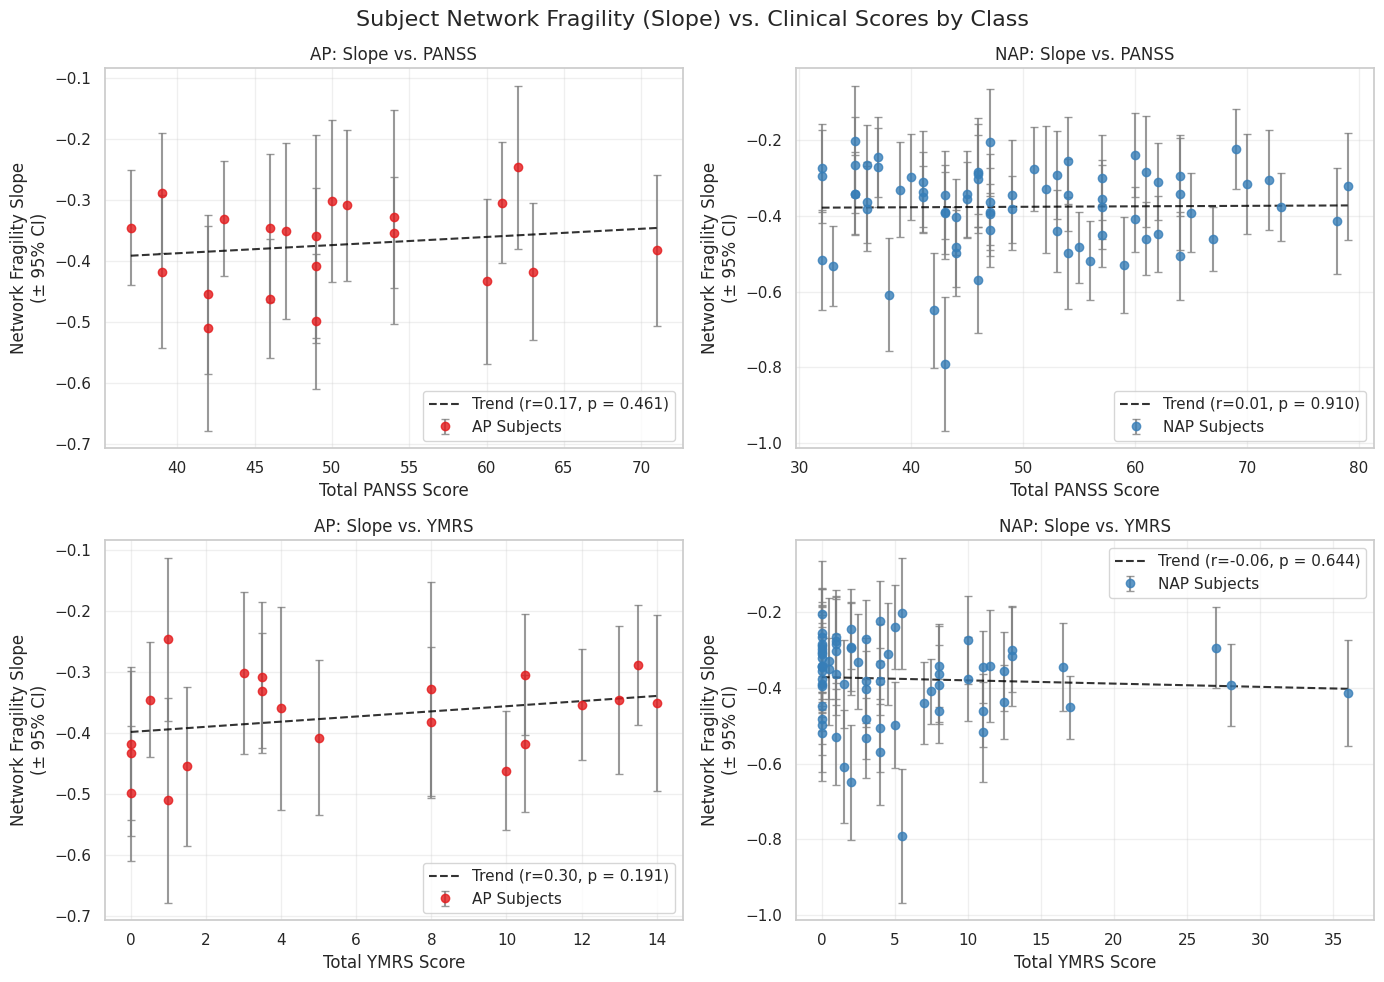

In [58]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import linregress

# 1. Collect the data: Slope, Standard Error, and Clinical Scores
data_list = []
groups = ['AP', 'NAP']

for group_name in groups:
    if group_name in p2h_maps:
        for subj_idx in p2h_maps[group_name].keys():
            p2o = p2o_maps[group_name][subj_idx]
            p2h = p2h_maps[group_name][subj_idx]
            
            # Calculate slope and its standard error
            slope, intercept, r_val, p_val, stderr = linregress(p2o, p2h)
            
            # Grab clinical scores (safely handling bounds)
            try:
                panss = panss_AP[subj_idx] if group_name == 'AP' else panss_NAP[subj_idx]
                ymrs = ymrs_AP[subj_idx] if group_name == 'AP' else ymrs_NAP[subj_idx]
            except IndexError:
                continue 
                
            data_list.append({
                "Subject_ID": f"{group_name}_{subj_idx}",
                "Group": group_name,
                "Slope": slope,
                "CI_95": stderr * 1.96, # 95% Confidence Interval
                "PANSS": panss,
                "YMRS": ymrs
            })

df_slopes = pd.DataFrame(data_list).dropna(subset=['PANSS', 'YMRS'])

# 2. Plotting setup: 2x2 Grid (Rows=Scores, Cols=Groups)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Subject Network Fragility (Slope) vs. Clinical Scores by Class", fontsize=16)

colors = {'AP': '#e41a1c', 'NAP': '#377eb8'}

def plot_group_errorbars(ax, group_name, clinical_col, x_label):
    group_df = df_slopes[df_slopes['Group'] == group_name]
    
    if group_df.empty:
        ax.set_title(f"{group_name} - No Data")
        return
        
    # Scatter plot with vertical error bars for this specific group
    ax.errorbar(
        x=group_df[clinical_col], 
        y=group_df['Slope'], 
        yerr=group_df['CI_95'], 
        fmt='o', 
        color=colors[group_name],
        ecolor='gray', 
        elinewidth=1.5,
        capsize=3,     
        alpha=0.8,
        label=f"{group_name} Subjects"
    )
    
    # Calculate group-specific trendline
    x_vals = group_df[clinical_col].values
    y_vals = group_df['Slope'].values
    group_slope, group_int, group_r, group_p, _ = linregress(x_vals, y_vals)
    
    x_range = np.linspace(x_vals.min(), x_vals.max(), 100)
    p_str = "p < 0.001" if group_p < 0.001 else f"p = {group_p:.3f}"
    
    ax.plot(x_range, group_slope * x_range + group_int, 
            color='black', linestyle='--', alpha=0.8, 
            label=f'Trend (r={group_r:.2f}, {p_str})')
    
    ax.set_title(f"{group_name}: Slope vs. {clinical_col}")
    ax.set_xlabel(x_label)
    ax.set_ylabel("Network Fragility Slope\n(± 95% CI)")
    ax.legend()
    ax.grid(True, alpha=0.3)

# Row 1: PANSS
plot_group_errorbars(axes[0, 0], 'AP', 'PANSS', 'Total PANSS Score')
plot_group_errorbars(axes[0, 1], 'NAP', 'PANSS', 'Total PANSS Score')

# Row 2: YMRS
plot_group_errorbars(axes[1, 0], 'AP', 'YMRS', 'Total YMRS Score')
plot_group_errorbars(axes[1, 1], 'NAP', 'YMRS', 'Total YMRS Score')

plt.tight_layout()
plt.show()

PCA

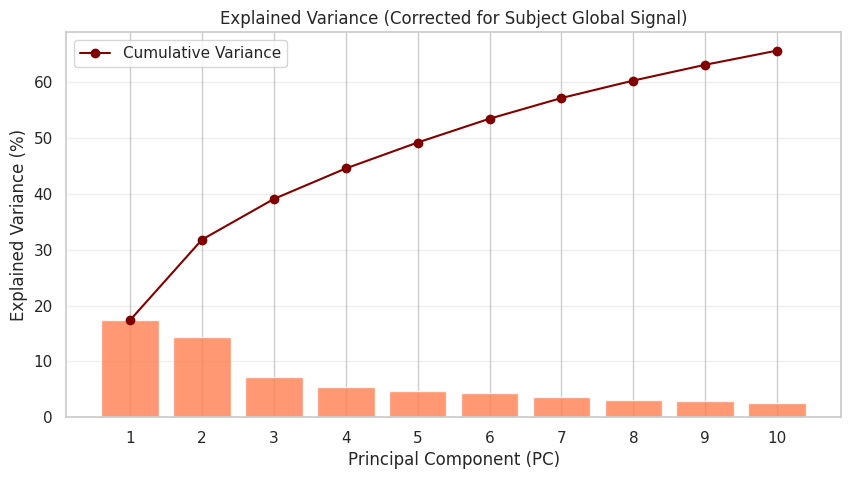

In [72]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# 1. Build the data matrix using P2O (Perturbability)
features_list = []
metadata_list = []

for group_name in ['AP', 'NAP']:
    if group_name in p2o_maps:
        for subj_idx, p2o_array in p2o_maps[group_name].items():
            features_list.append(p2o_array)
            metadata_list.append({
                "Subject_ID": f"{group_name}_{subj_idx}",
                "Group": group_name,
                "Subj_Idx": subj_idx
            })

X_raw = np.array(features_list)
df_pca_meta = pd.DataFrame(metadata_list)

# --- THE KEY FIX: Subject-level mean centering (Row-wise) ---
# Calculate the mean for each subject (across their regions) and subtract it
subject_means = np.mean(X_raw, axis=1, keepdims=True)
X_centered = X_raw - subject_means

# 2. Standardize the data across subjects (Column-wise)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_centered)

# 3. Apply PCA
n_components = 10 # Bumping up to 10 to see the new distribution clearly
pca = PCA(n_components=n_components)
X_pca = pca.fit_transform(X_scaled)

for i in range(n_components):
    df_pca_meta[f'PC{i+1}'] = X_pca[:, i]

# 4. Plot the newly distributed explained variance
plt.figure(figsize=(10, 5))
plt.bar(range(1, n_components + 1), pca.explained_variance_ratio_ * 100, color='coral', alpha=0.8)
plt.plot(range(1, n_components + 1), np.cumsum(pca.explained_variance_ratio_ * 100), marker='o', color='maroon', label='Cumulative Variance')

plt.title('Explained Variance (Corrected for Subject Global Signal)')
plt.xlabel('Principal Component (PC)')
plt.ylabel('Explained Variance (%)')
plt.xticks(range(1, n_components + 1))
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

In [70]:
# 1. Encontrar el PC dominante para cada sujeto (ignorar el signo usando abs)
pc_columns = [f'PC{i+1}' for i in range(n_components)]
dominant_pc_idx = np.argmax(np.abs(df_pca_meta[pc_columns].values), axis=1)

# Asignar la categoría (Ej: "PC1", "PC2", etc.)
df_pca_meta['Dominant_Profile'] = [f'PC{idx+1}' for idx in dominant_pc_idx]

# 2. Mapear los scores clínicos a este DataFrame
panss_scores = []
ymrs_scores = []

for idx, row in df_pca_meta.iterrows():
    g = row['Group']
    s_idx = row['Subj_Idx']
    
    try:
        if g == 'AP':
            panss_scores.append(panss_AP[s_idx])
            ymrs_scores.append(ymrs_AP[s_idx])
        else:
            panss_scores.append(panss_NAP[s_idx])
            ymrs_scores.append(ymrs_NAP[s_idx])
    except IndexError:
        panss_scores.append(np.nan)
        ymrs_scores.append(np.nan)

df_pca_meta['PANSS'] = panss_scores
df_pca_meta['YMRS'] = ymrs_scores

# Limpiar sujetos sin datos clínicos
df_pca_clin = df_pca_meta.dropna(subset=['PANSS', 'YMRS']).copy()

# Ver cuántos sujetos cayeron en cada perfil
print(df_pca_clin['Dominant_Profile'].value_counts())

Dominant_Profile
PC1    41
PC2    25
PC3     7
PC4     6
PC5     4
PC6     4
PC7     4
PC8     1
Name: count, dtype: int64


/tmp/ipykernel_180985/4108663228.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_pca_clin, x='Dominant_Profile', y='PANSS', order=order, ax=axes[0], palette='Set2')
/tmp/ipykernel_180985/4108663228.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_pca_clin, x='Dominant_Profile', y='YMRS', order=order, ax=axes[1], palette='Set2')


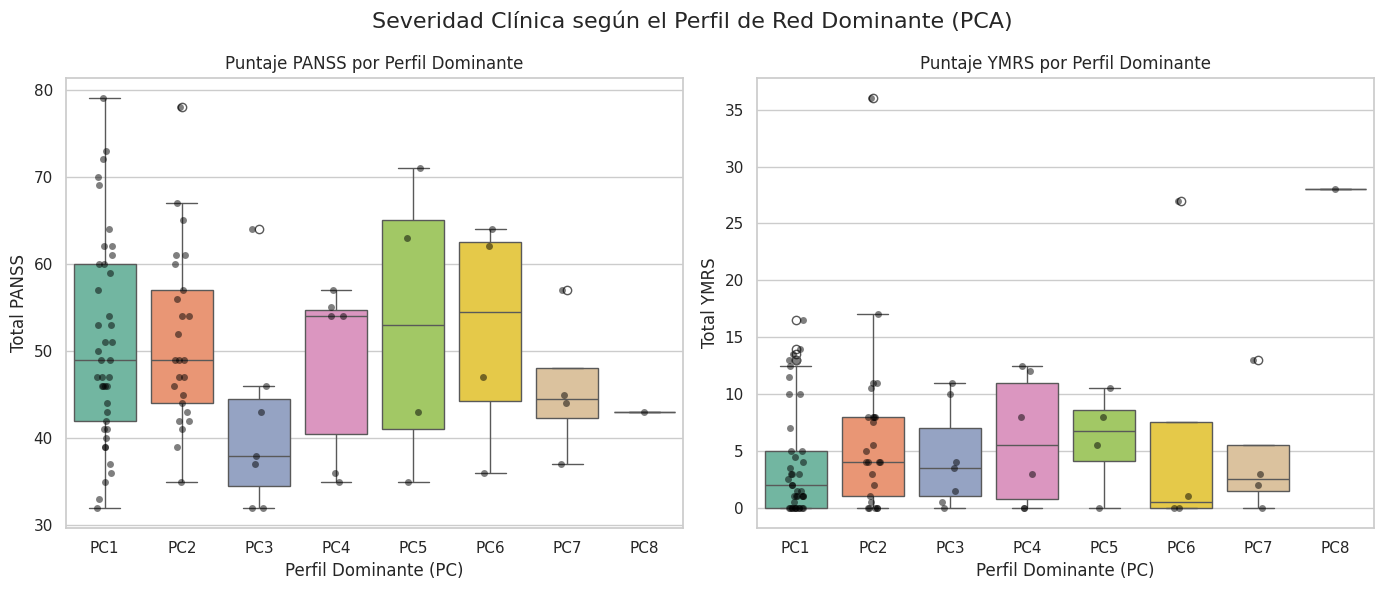

In [ ]:
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Severidad Clínica según el Perfil de Red Dominante (PCA)", fontsize=16)

# Ordenar las categorías lógicamente (PC1, PC2, etc.)
order = sorted(df_pca_clin['Dominant_Profile'].unique())

# Subplot 1: PANSS
sns.boxplot(data=df_pca_clin, x='Dominant_Profile', y='PANSS', order=order, ax=axes[0], palette='Set2')
sns.stripplot(data=df_pca_clin, x='Dominant_Profile', y='PANSS', order=order, ax=axes[0], color='black', alpha=0.5, jitter=True)
axes[0].set_title("Puntaje PANSS por Perfil Dominante")
axes[0].set_xlabel("Perfil Dominante (PC)")
axes[0].set_ylabel("Total PANSS")

# Subplot 2: YMRS
sns.boxplot(data=df_pca_clin, x='Dominant_Profile', y='YMRS', order=order, ax=axes[1], palette='Set2')
sns.stripplot(data=df_pca_clin, x='Dominant_Profile', y='YMRS', order=order, ax=axes[1], color='black', alpha=0.5, jitter=True)
axes[1].set_title("Puntaje YMRS por Perfil Dominante")
axes[1].set_xlabel("Perfil Dominante (PC)")
axes[1].set_ylabel("Total YMRS")

plt.tight_layout()
plt.show()